
# C01 — Surface-Trace Gap Characterization

## Scientific question

Before testing more detectors, establish the **simple, non-structural human–LLM differences**
that a QuillBot-like rewrite can plausibly change.

The working decomposition is

\[
\text{machine-writing signal}
=
\text{surface/local cues}
+
\text{recurrence cues}
+
\text{structural dependency cues}
+
\text{residual}.
\]

C01 does **not** optimize against any detector and does **not** yet rewrite text.

It asks four pre-intervention questions:

1. Which simple surface measurements exhibit a reproducible matched human–LLM gap?
2. Are those measurements sufficiently predictive to support a transparent surface-only detector?
3. How redundant are the surface measurements with one another?
4. Does the existing structural intervention from C00b (`L050`) accidentally move these
   surface measurements, or is its effect on \(U\) relatively selective?

Only measurements that survive this characterization become candidates for the later
surface-control intervention.

## Frozen evaluation population

Reuse the exact 60 C00 sources:

- 30 RAID news sources;
- 30 RAID Wikipedia sources;
- machine text: unattenuated C00b `L000`;
- matched human text: the RAID human source for the same `source_id`;
- structural comparison: C00b `L050`.

No detector scores are used to select metrics or thresholds.

## Predeclared metric families

### Lexical form

- mean alphabetic word length;
- long-word rate (\(\ge 8\) letters);
- moving-average type-token ratio (`MATTR50`);
- hapax-token rate;
- normalized lexical entropy.

### Function/style markers

- function-word rate;
- contraction rate.

### Sentence rhythm

- mean sentence length in words;
- coefficient of variation of sentence length;
- normalized adjacent sentence-length change.

### Punctuation

Per 100 words:

- comma rate;
- semicolon/colon rate;
- dash rate;
- parenthesis rate.

### Local recurrence

- repeated 4-gram position fraction;
- distinct 4-gram fraction;
- maximum repeated-4gram rate.

`word_count` and `sentence_count` are retained as descriptive covariates but are **not**
candidate humanization targets.

## Statistical gate

For each candidate metric, use the paired source-level difference

\[
\Delta_m = M_m(X_{\rm L000}) - M_m(X_H).
\]

Report:

- paired mean gap;
- paired bootstrap 95% CI;
- standardized paired effect \(d_z=\bar\Delta/s_\Delta\);
- two-sided sign-flip permutation \(p\)-value;
- Benjamini–Hochberg FDR across the predeclared candidate metrics.

A metric is marked `candidate_surface_control=True` only when:

\[
q_{\rm BH}<0.05,
\qquad
|\bar\Delta|>0,
\qquad
|d_z|\ge 0.35.
\]

This gate is based only on the human–machine gap, **not detector performance**.


In [1]:

from pathlib import Path
from collections import Counter
import hashlib
import math
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, balanced_accuracy_score

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
RESULTS = ROOT / "results"

C00_DIR = RESULTS / "causal" / "C00_effective_history_gap_closure"
C00B_DIR = RESULTS / "causal" / "C00b_soft_self_history_attenuation"
C00C_DIR = RESULTS / "causal" / "C00c_detector_transfer_under_history_humanization"

OUT = RESULTS / "causal" / "C01_surface_trace_gap_characterization"
OUT.mkdir(parents=True, exist_ok=True)

GEN_PATH = C00B_DIR / "generations.parquet"
PROMPT_PATH = C00_DIR / "frozen_prompts.parquet"

assert GEN_PATH.exists(), f"Missing {GEN_PATH}"
assert PROMPT_PATH.exists(), f"Missing {PROMPT_PATH}"

generations = pd.read_parquet(GEN_PATH).copy()
prompts = pd.read_parquet(PROMPT_PATH).copy()

for df in [generations, prompts]:
    df["source_id"] = df["source_id"].astype(str)

SOURCE_IDS = sorted(generations["source_id"].unique())

assert len(SOURCE_IDS) == 60
assert {"L000", "L050"}.issubset(set(generations["condition"]))

N_BOOT = 10_000
N_PERM = 20_000
SEED = 20260902

print("ROOT:", ROOT)
print("OUT:", OUT)
print("sources:", len(SOURCE_IDS))


ROOT: ..
OUT: ../results/causal/C01_surface_trace_gap_characterization
sources: 60



## 1. Recover the matched human texts

Prefer the cache created by C00c when available. Otherwise stream the same cached RAID
training CSV used by the earlier RAID notebooks and recover exactly the 60 human rows.

This is only text recovery; no detector calibration data enter C01.


In [2]:

HUMAN_CACHE_CANDIDATES = [
    C00C_DIR / "matched_human_texts.parquet",
    OUT / "matched_human_texts.parquet",
]

human_cache = next(
    (p for p in HUMAN_CACHE_CANDIDATES if p.exists()),
    None,
)

if human_cache is not None:
    human_text = pd.read_parquet(human_cache).copy()
    human_text["source_id"] = human_text["source_id"].astype(str)
    print("loaded:", human_cache)

else:
    RAID_CSV = Path.home() / ".cache" / "raid" / "train.csv"
    assert RAID_CSV.exists(), (
        f"Missing {RAID_CSV}. "
        "Restore the RAID cache used by notebooks 16/17."
    )

    wanted = set(SOURCE_IDS)
    pieces = []

    for chunk in pd.read_csv(
        RAID_CSV,
        usecols=[
            "id",
            "model",
            "attack",
            "domain",
            "title",
            "generation",
        ],
        chunksize=100_000,
    ):
        keep = chunk[
            chunk["id"].astype(str).isin(wanted)
            & chunk["model"].astype(str).eq("human")
            & chunk["attack"].astype(str).eq("none")
        ].copy()

        if len(keep):
            pieces.append(keep)

        if pieces:
            found = set(
                pd.concat(pieces, ignore_index=True)["id"].astype(str)
            )
            if wanted.issubset(found):
                break

    raw_h = pd.concat(pieces, ignore_index=True).drop_duplicates("id")

    human_text = (
        raw_h[
            ["id", "domain", "title", "generation"]
        ]
        .rename(columns={
            "id": "source_id",
            "generation": "text",
        })
        .copy()
    )

    human_text["source_id"] = human_text["source_id"].astype(str)
    human_text.to_parquet(
        OUT / "matched_human_texts.parquet",
        index=False,
    )

assert human_text["source_id"].nunique() == 60
assert set(human_text["source_id"]) == set(SOURCE_IDS)

display(
    human_text.groupby("domain")
    .size()
    .rename("n")
    .to_frame()
)


loaded: ../results/causal/C00c_detector_transfer_under_history_humanization/matched_human_texts.parquet


,n
domain,
news,30
wiki,30



## 2. Freeze the three-way corpus

For each source:

- `human`: matched RAID human document;
- `L000`: ordinary unattenuated Qwen generation;
- `L050`: soft-history attenuation at \(\lambda=0.5\).

All surface measurements are computed from the complete decoded text. There is no
384-token eligibility gate because these measurements do not require the RELIC scorer.


In [3]:

machine = generations[
    generations["condition"].isin(["L000", "L050"])
][
    ["source_id", "condition", "generated_text"]
].rename(columns={"generated_text": "text"}).copy()

human = human_text[
    ["source_id", "text"]
].copy()
human["condition"] = "human"

corpus = pd.concat(
    [human, machine],
    ignore_index=True,
)

corpus["source_id"] = corpus["source_id"].astype(str)
corpus["text"] = corpus["text"].astype(str)

domain_map = (
    human_text[
        ["source_id", "domain"]
    ]
    .drop_duplicates("source_id")
    .set_index("source_id")["domain"]
)

corpus["domain"] = corpus["source_id"].map(domain_map)

assert not corpus.duplicated(["source_id", "condition"]).any()
assert len(corpus) == 60 * 3

display(
    corpus.groupby(["domain", "condition"])
    .size()
    .rename("n")
    .to_frame()
)


n
domain condition    
news   L000       30
       L050       30
       human      30
wiki   L000       30
       L050       30
       human      30


## 3. Surface metric definitions

The implementation intentionally avoids semantic embeddings, language-model likelihoods,
POS parsers, or detector outputs.

The goal is to isolate cheap cues that can later be altered without changing the
document's central claims or discourse plan.


In [4]:

WORD_RE = re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?")
SENT_SPLIT_RE = re.compile(r"(?<=[.!?])(?:[\"')\]]+)?\s+")

# Closed-class/function words only. This is deliberately fixed and transparent.
FUNCTION_WORDS = {
    "a","an","the","and","or","but","if","while","although","though","because","since",
    "as","of","to","in","on","at","by","for","from","with","without","about","into",
    "through","during","before","after","above","below","between","among","against",
    "is","am","are","was","were","be","been","being","do","does","did","have","has","had",
    "can","could","may","might","must","shall","should","will","would",
    "i","me","my","mine","we","us","our","ours","you","your","yours",
    "he","him","his","she","her","hers","it","its","they","them","their","theirs",
    "this","that","these","those","who","whom","whose","which","what",
    "where","when","why","how","not","no","nor","so","than","then","there","here",
}

CONTRACTION_RE = re.compile(
    r"\b(?:[A-Za-z]+n't|[A-Za-z]+'(?:re|ve|ll|d|m|s))\b",
    flags=re.IGNORECASE,
)

def words(text):
    return [w.lower() for w in WORD_RE.findall(str(text))]

def sentences(text):
    text = re.sub(r"\s+", " ", str(text)).strip()
    if not text:
        return []
    s = [
        x.strip()
        for x in SENT_SPLIT_RE.split(text)
        if x.strip()
    ]
    return s if s else [text]

def mattr(tokens, window=50):
    n = len(tokens)
    if n == 0:
        return np.nan
    if n <= window:
        return len(set(tokens)) / n

    vals = [
        len(set(tokens[i:i+window])) / window
        for i in range(n - window + 1)
    ]
    return float(np.mean(vals))

def lexical_entropy_norm(tokens):
    n = len(tokens)
    if n <= 1:
        return np.nan

    counts = np.array(
        list(Counter(tokens).values()),
        dtype=float,
    )
    p = counts / counts.sum()

    H = -np.sum(p * np.log(p))
    V = len(counts)

    if V <= 1:
        return 0.0

    return float(H / np.log(V))

def ngram_surface(tokens, n=4):
    if len(tokens) < n:
        return {
            "repeat4_fraction": np.nan,
            "distinct4": np.nan,
            "max_repeat4_rate": np.nan,
        }

    grams = [
        tuple(tokens[i:i+n])
        for i in range(len(tokens) - n + 1)
    ]

    counts = Counter(grams)
    N = len(grams)

    repeated_positions = sum(
        c for c in counts.values()
        if c > 1
    )

    return {
        "repeat4_fraction":
            repeated_positions / N,

        "distinct4":
            len(counts) / N,

        "max_repeat4_rate":
            max(counts.values()) / N,
    }

def rate_per_100(char_count, n_words):
    return (
        100.0 * char_count / n_words
        if n_words > 0
        else np.nan
    )

def surface_features(text):
    text = str(text)
    toks = words(text)
    sents = sentences(text)

    n_words = len(toks)
    sent_lens = np.array(
        [len(words(s)) for s in sents],
        dtype=float,
    )
    sent_lens = sent_lens[sent_lens > 0]

    counts = Counter(toks)

    if n_words:
        hapax_tokens = sum(
            c for c in counts.values()
            if c == 1
        )
        function_rate = np.mean(
            [w in FUNCTION_WORDS for w in toks]
        )
        long_word_rate = np.mean(
            [len(w) >= 8 for w in toks]
        )
        mean_word_len = np.mean(
            [len(w) for w in toks]
        )
    else:
        hapax_tokens = np.nan
        function_rate = np.nan
        long_word_rate = np.nan
        mean_word_len = np.nan

    if len(sent_lens):
        mean_sentence_words = float(sent_lens.mean())
        sentence_cv = (
            float(sent_lens.std(ddof=1) / sent_lens.mean())
            if len(sent_lens) >= 2 and sent_lens.mean() > 0
            else 0.0
        )

        adjacent_sentence_change = (
            float(
                np.mean(np.abs(np.diff(sent_lens)))
                / sent_lens.mean()
            )
            if len(sent_lens) >= 2 and sent_lens.mean() > 0
            else 0.0
        )
    else:
        mean_sentence_words = np.nan
        sentence_cv = np.nan
        adjacent_sentence_change = np.nan

    result = {
        "word_count": n_words,
        "sentence_count": len(sent_lens),

        "mean_word_len": mean_word_len,
        "long_word_rate": long_word_rate,
        "mattr50": mattr(toks, 50),
        "hapax_token_rate": (
            hapax_tokens / n_words
            if n_words
            else np.nan
        ),
        "lexical_entropy_norm": lexical_entropy_norm(toks),

        "function_word_rate": function_rate,
        "contraction_rate_per100": rate_per_100(
            len(CONTRACTION_RE.findall(text)),
            n_words,
        ),

        "mean_sentence_words": mean_sentence_words,
        "sentence_cv": sentence_cv,
        "adjacent_sentence_change": adjacent_sentence_change,

        "comma_rate_per100": rate_per_100(
            text.count(","),
            n_words,
        ),
        "semicolon_colon_rate_per100": rate_per_100(
            text.count(";") + text.count(":"),
            n_words,
        ),
        "dash_rate_per100": rate_per_100(
            text.count("—") + text.count("–"),
            n_words,
        ),
        "paren_rate_per100": rate_per_100(
            text.count("(") + text.count(")"),
            n_words,
        ),
    }

    result.update(
        ngram_surface(toks, 4)
    )

    return result


FEATURE_COLS = [
    "mean_word_len",
    "long_word_rate",
    "mattr50",
    "hapax_token_rate",
    "lexical_entropy_norm",
    "function_word_rate",
    "contraction_rate_per100",
    "mean_sentence_words",
    "sentence_cv",
    "adjacent_sentence_change",
    "comma_rate_per100",
    "semicolon_colon_rate_per100",
    "dash_rate_per100",
    "paren_rate_per100",
    "repeat4_fraction",
    "distinct4",
    "max_repeat4_rate",
]

DESCRIPTIVE_COLS = [
    "word_count",
    "sentence_count",
]


In [5]:

rows = []

for _, r in corpus.iterrows():
    rows.append({
        "source_id": str(r["source_id"]),
        "domain": r["domain"],
        "condition": r["condition"],
        **surface_features(r["text"]),
    })

surface = pd.DataFrame(rows)

assert len(surface) == 180
assert not surface.duplicated(["source_id", "condition"]).any()

surface.to_parquet(
    OUT / "surface_features_long.parquet",
    index=False,
)

print("saved:", OUT / "surface_features_long.parquet")

display(
    surface.groupby("condition")[
        DESCRIPTIVE_COLS + FEATURE_COLS
    ]
    .mean()
    .T
)


saved: ../results/causal/C01_surface_trace_gap_characterization/surface_features_long.parquet


condition,L000,L050,human
word_count,280.600000,255.966667,417.850000
sentence_count,13.150000,11.816667,20.550000
mean_word_len,4.933297,4.935934,4.868386
long_word_rate,0.187455,0.185988,0.171584
mattr50,0.742616,0.738983,0.794287
hapax_token_rate,0.306241,0.324626,0.369907
lexical_entropy_norm,0.900497,0.903652,0.914252
function_word_rate,0.430676,0.429229,0.393702
contraction_rate_per100,2.423975,2.308837,0.752386
mean_sentence_words,24.330093,24.872548,21.110927



## 4. Paired human–L000 gaps

The unit of analysis is always the matched source.

The permutation test flips the sign of the 60 paired differences. This avoids normality
assumptions while preserving the paired design.


In [6]:

def paired_bootstrap_ci(d, n_boot=N_BOOT, seed=SEED):
    d = np.asarray(d, dtype=float)
    d = d[np.isfinite(d)]

    rr = np.random.default_rng(seed)
    bs = np.empty(n_boot)

    for b in range(n_boot):
        ix = rr.integers(0, len(d), len(d))
        bs[b] = d[ix].mean()

    return (
        float(np.quantile(bs, 0.025)),
        float(np.quantile(bs, 0.975)),
    )

def sign_flip_pvalue(d, n_perm=N_PERM, seed=SEED):
    d = np.asarray(d, dtype=float)
    d = d[np.isfinite(d)]

    obs = abs(d.mean())

    rr = np.random.default_rng(seed)
    exceed = 0

    # Chunk to avoid constructing a huge matrix.
    chunk = 2000
    done = 0

    while done < n_perm:
        m = min(chunk, n_perm - done)

        signs = rr.choice(
            [-1.0, 1.0],
            size=(m, len(d)),
        )

        means = np.abs(
            (signs * d[None, :]).mean(axis=1)
        )

        exceed += int(
            np.sum(means >= obs)
        )

        done += m

    return (exceed + 1) / (n_perm + 1)

def bh_qvalues(p):
    p = np.asarray(p, dtype=float)
    n = len(p)

    order = np.argsort(p)
    ranked = p[order]

    q_ranked = ranked * n / np.arange(1, n + 1)
    q_ranked = np.minimum.accumulate(
        q_ranked[::-1]
    )[::-1]
    q_ranked = np.clip(q_ranked, 0, 1)

    q = np.empty(n)
    q[order] = q_ranked
    return q


wide = surface.pivot(
    index="source_id",
    columns="condition",
    values=FEATURE_COLS,
)

gap_rows = []

for i, metric in enumerate(FEATURE_COLS):
    h = wide[(metric, "human")]
    a = wide[(metric, "L000")]

    pair = pd.concat(
        [h.rename("human"), a.rename("L000")],
        axis=1,
    ).dropna()

    d = (
        pair["L000"] - pair["human"]
    ).to_numpy(float)

    lo, hi = paired_bootstrap_ci(
        d,
        seed=SEED + 1000 + i,
    )

    p = sign_flip_pvalue(
        d,
        seed=SEED + 2000 + i,
    )

    sd = d.std(ddof=1)

    gap_rows.append({
        "metric": metric,
        "n": len(d),
        "human_mean": pair["human"].mean(),
        "L000_mean": pair["L000"].mean(),
        "gap_L000_minus_human": d.mean(),
        "ci_low": lo,
        "ci_high": hi,
        "paired_dz": (
            d.mean() / sd
            if sd > 0
            else np.nan
        ),
        "p_signflip": p,
    })

surface_gaps = pd.DataFrame(gap_rows)
surface_gaps["q_BH"] = bh_qvalues(
    surface_gaps["p_signflip"]
)

surface_gaps["candidate_surface_control"] = (
    surface_gaps["q_BH"].lt(0.05)
    & surface_gaps["paired_dz"].abs().ge(0.35)
)

surface_gaps = surface_gaps.sort_values(
    ["candidate_surface_control", "paired_dz"],
    ascending=[False, False],
).reset_index(drop=True)

surface_gaps.to_csv(
    OUT / "human_L000_surface_gaps.csv",
    index=False,
)

display(surface_gaps)


,metric,n,human_mean,L000_mean,gap_L000_minus_human,ci_low,ci_high,paired_dz,p_signflip,q_BH,candidate_surface_control
0,repeat4_fraction,60,0.018880,0.180975,0.162095,0.110564,0.221104,0.731679,0.000050,0.000170,True
1,function_word_rate,60,0.393702,0.430676,0.036974,0.013091,0.058882,0.407143,0.001900,0.004037,True
2,mattr50,60,0.794287,0.742616,-0.051672,-0.086917,-0.019355,-0.392855,0.001150,0.002793,True
3,paren_rate_per100,60,1.977037,0.595619,-1.381418,-2.260070,-0.606972,-0.424402,0.000800,0.002267,True
4,distinct4,60,0.989545,0.883504,-0.106041,-0.153397,-0.065760,-0.594528,0.000050,0.000170,True
5,adjacent_sentence_change,60,0.503415,0.275572,-0.227843,-0.300917,-0.163249,-0.833614,0.000050,0.000170,True
6,sentence_cv,60,0.451199,0.265438,-0.185762,-0.246042,-0.134160,-0.834019,0.000050,0.000170,True
7,max_repeat4_rate,60,0.005991,0.032112,0.026121,0.010091,0.047709,0.349570,0.000050,0.000170,False
8,contraction_rate_per100,60,0.752386,2.423975,1.671589,0.301566,3.349446,0.270189,0.044048,0.074881,False
9,long_word_rate,60,0.171584,0.187455,0.015871,-0.012025,0.041586,0.148556,0.258537,0.313938,False



## 5. Domain sensitivity

A surface cue is more compelling when its direction is not produced entirely by one of
the two writing domains.

For every metric, report the paired gap separately for news and Wikipedia. This is a
sensitivity analysis rather than an additional significance gate.


In [7]:

domain_rows = []

for domain in ["news", "wiki"]:
    ids = set(
        surface.loc[
            surface["domain"].eq(domain),
            "source_id",
        ].astype(str)
    )

    for metric in FEATURE_COLS:
        h = wide.loc[
            wide.index.astype(str).isin(ids),
            (metric, "human"),
        ]
        a = wide.loc[
            wide.index.astype(str).isin(ids),
            (metric, "L000"),
        ]

        pair = pd.concat(
            [h.rename("human"), a.rename("L000")],
            axis=1,
        ).dropna()

        d = (
            pair["L000"] - pair["human"]
        ).to_numpy(float)

        domain_rows.append({
            "domain": domain,
            "metric": metric,
            "n": len(d),
            "gap_L000_minus_human": d.mean(),
            "paired_dz": (
                d.mean() / d.std(ddof=1)
                if len(d) > 1 and d.std(ddof=1) > 0
                else np.nan
            ),
        })

domain_gaps = pd.DataFrame(domain_rows)

domain_pivot = domain_gaps.pivot(
    index="metric",
    columns="domain",
    values="gap_L000_minus_human",
)

domain_pivot["same_direction"] = (
    np.sign(domain_pivot["news"])
    == np.sign(domain_pivot["wiki"])
)

display(
    surface_gaps[
        [
            "metric",
            "gap_L000_minus_human",
            "paired_dz",
            "q_BH",
            "candidate_surface_control",
        ]
    ]
    .merge(
        domain_pivot.reset_index(),
        on="metric",
        how="left",
    )
)

domain_gaps.to_csv(
    OUT / "human_L000_surface_gaps_by_domain.csv",
    index=False,
)


,metric,gap_L000_minus_human,paired_dz,q_BH,candidate_surface_control,news,wiki,same_direction
0,repeat4_fraction,0.162095,0.731679,0.000170,True,0.155275,0.168915,True
1,function_word_rate,0.036974,0.407143,0.004037,True,0.021013,0.052935,True
2,mattr50,-0.051672,-0.392855,0.002793,True,-0.062580,-0.040764,True
3,paren_rate_per100,-1.381418,-0.424402,0.002267,True,-0.126694,-2.636143,True
4,distinct4,-0.106041,-0.594528,0.000170,True,-0.086869,-0.125212,True
5,adjacent_sentence_change,-0.227843,-0.833614,0.000170,True,-0.162671,-0.293015,True
6,sentence_cv,-0.185762,-0.834019,0.000170,True,-0.129817,-0.241706,True
7,max_repeat4_rate,0.026121,0.349570,0.000170,False,0.005862,0.046380,True
8,contraction_rate_per100,1.671589,0.270189,0.074881,False,0.099312,3.243866,True
9,long_word_rate,0.015871,0.148556,0.313938,False,0.068454,-0.036712,False



## 6. Do these simple metrics actually support detection?

Construct a deliberately transparent **surface-only logistic detector** using exactly the
predeclared metrics.

This is **not** used to choose the intervention. It serves only as a relevance check:
if the surface feature family cannot distinguish the matched human/L000 texts even in a
detector that has direct access to it, there is little reason to prioritize it as a
detector-control baseline.

Evaluation uses 5-fold `GroupKFold` by `source_id`, so the human and machine document from
a source always remain in the same fold.

Report:

- out-of-fold AUROC;
- balanced accuracy at a fixed probability threshold of 0.5;
- standardized full-data coefficients only as descriptive feature weights.


In [8]:

det_df = surface[
    surface["condition"].isin(["human", "L000"])
].copy()

X = det_df[FEATURE_COLS].copy()
X = X.fillna(
    X.median(numeric_only=True)
)

y = (
    det_df["condition"]
    .eq("L000")
    .astype(int)
    .to_numpy()
)

groups = det_df["source_id"].astype(str).to_numpy()

pipe = Pipeline([
    ("scale", StandardScaler()),
    (
        "clf",
        LogisticRegression(
            C=1.0,
            max_iter=5000,
            random_state=SEED,
        ),
    ),
])

cv = GroupKFold(n_splits=5)

oof_prob = cross_val_predict(
    pipe,
    X,
    y,
    groups=groups,
    cv=cv,
    method="predict_proba",
)[:, 1]

oof_pred = (
    oof_prob >= 0.5
).astype(int)

surface_detector_auc = roc_auc_score(
    y,
    oof_prob,
)

surface_detector_bacc = balanced_accuracy_score(
    y,
    oof_pred,
)

print(
    "surface-only OOF AUROC:",
    surface_detector_auc,
)

print(
    "surface-only OOF balanced accuracy @0.5:",
    surface_detector_bacc,
)

# Descriptive coefficient fit on all 120 documents.
pipe.fit(X, y)

coef = (
    pipe.named_steps["clf"]
    .coef_[0]
)

coef_df = pd.DataFrame({
    "metric": FEATURE_COLS,
    "standardized_logit_coef": coef,
    "abs_coef": np.abs(coef),
}).sort_values(
    "abs_coef",
    ascending=False,
)

display(coef_df)

pd.DataFrame({
    "source_id": groups,
    "condition": det_df["condition"].to_numpy(),
    "label_machine": y,
    "oof_machine_probability": oof_prob,
}).to_csv(
    OUT / "surface_only_detector_oof.csv",
    index=False,
)

coef_df.to_csv(
    OUT / "surface_only_detector_coefficients.csv",
    index=False,
)


surface-only OOF AUROC: 0.9738888888888888
surface-only OOF balanced accuracy @0.5: 0.925


,metric,standardized_logit_coef,abs_coef
9,adjacent_sentence_change,-1.421971,1.421971
14,repeat4_fraction,1.260481,1.260481
16,max_repeat4_rate,1.202827,1.202827
2,mattr50,-1.112968,1.112968
0,mean_word_len,1.007804,1.007804
5,function_word_rate,0.936863,0.936863
3,hapax_token_rate,-0.851773,0.851773
15,distinct4,-0.816060,0.816060
8,sentence_cv,-0.803626,0.803626
6,contraction_rate_per100,0.770343,0.770343



## 7. Redundancy among the candidate surface traces

The larger project hypothesizes that many apparent detector cues collapse to a small
number of underlying axes.

Compute correlations on pooled `human + L000` documents after z-scoring each metric.
The goal is not feature selection here; it is to see whether the predeclared surface
measurements already form obvious redundant blocks.


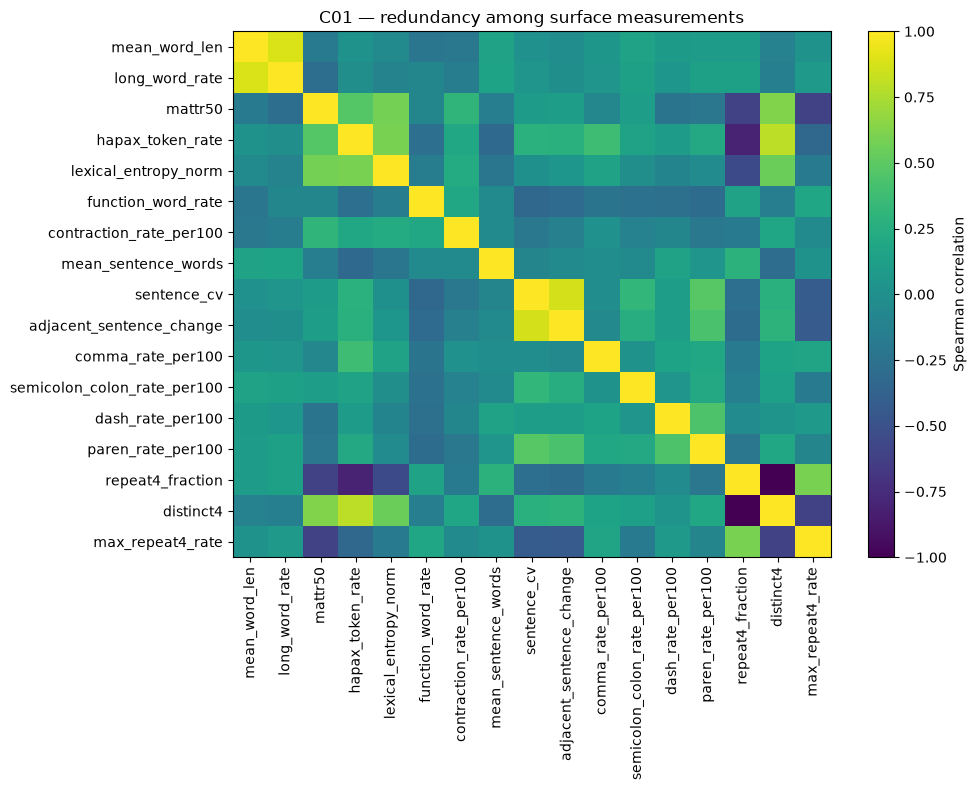

saved: ../results/causal/C01_surface_trace_gap_characterization/surface_metric_correlation.png


In [9]:

corr_data = det_df[
    FEATURE_COLS
].copy()

corr_data = corr_data.fillna(
    corr_data.median(numeric_only=True)
)

corr = corr_data.corr(
    method="spearman"
)

corr.to_csv(
    OUT / "surface_metric_spearman_corr.csv"
)

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(
    corr.to_numpy(),
    vmin=-1,
    vmax=1,
    aspect="auto",
)

ax.set_xticks(
    np.arange(len(FEATURE_COLS))
)
ax.set_xticklabels(
    FEATURE_COLS,
    rotation=90,
)

ax.set_yticks(
    np.arange(len(FEATURE_COLS))
)
ax.set_yticklabels(
    FEATURE_COLS,
)

fig.colorbar(
    im,
    ax=ax,
    label="Spearman correlation",
)

ax.set_title(
    "C01 — redundancy among surface measurements"
)

fig.tight_layout()

p = OUT / "surface_metric_correlation.png"
fig.savefig(
    p,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("saved:", p)



## 8. Does the structural C00b intervention also move surface cues?

This is an important selectivity check.

For each surface metric \(m\), define the human gap under ordinary generation

\[
g_m
=
E[M_m(X_{\rm L000})-M_m(X_H)].
\]

Then define the `L050` gap-closure ratio

\[
C^{\rm surface}_m
=
1-
\frac{
E[M_m(X_{\rm L050})-M_m(X_H)]
}{
E[M_m(X_{\rm L000})-M_m(X_H)]
}.
\]

This is interpreted only when the baseline surface gap is non-trivial.

If `L050` strongly humanizes many simple surface cues, then its detector effect cannot be
attributed uniquely to dependency range. If the surface cues remain mostly fixed while
\(U\) moves, that strengthens the interpretation of C00b as a structural intervention.


In [10]:

collateral_rows = []

for i, metric in enumerate(FEATURE_COLS):
    triple = pd.concat(
        [
            wide[(metric, "human")].rename("human"),
            wide[(metric, "L000")].rename("L000"),
            wide[(metric, "L050")].rename("L050"),
        ],
        axis=1,
    ).dropna()

    h = triple["human"].to_numpy(float)
    b = triple["L000"].to_numpy(float)
    t = triple["L050"].to_numpy(float)

    baseline_gap = float(
        np.mean(b - h)
    )

    treatment_gap = float(
        np.mean(t - h)
    )

    shift = float(
        np.mean(t - b)
    )

    closure = (
        1.0 - treatment_gap / baseline_gap
        if abs(baseline_gap) > 1e-12
        else np.nan
    )

    rr = np.random.default_rng(
        SEED + 5000 + i
    )

    bs_shift = np.empty(N_BOOT)
    bs_closure = np.full(
        N_BOOT,
        np.nan,
    )

    for k in range(N_BOOT):
        ix = rr.integers(
            0,
            len(triple),
            len(triple),
        )

        bg = np.mean(
            b[ix] - h[ix]
        )

        tg = np.mean(
            t[ix] - h[ix]
        )

        bs_shift[k] = np.mean(
            t[ix] - b[ix]
        )

        if abs(bg) > 1e-12:
            bs_closure[k] = (
                1.0 - tg / bg
            )

    valid = np.isfinite(
        bs_closure
    )

    collateral_rows.append({
        "metric": metric,
        "n": len(triple),
        "baseline_gap_L000_minus_human": baseline_gap,
        "L050_gap_minus_human": treatment_gap,
        "L050_minus_L000": shift,
        "shift_ci_low": np.quantile(bs_shift, 0.025),
        "shift_ci_high": np.quantile(bs_shift, 0.975),
        "surface_gap_closure": closure,
        "closure_ci_low": (
            np.quantile(bs_closure[valid], 0.025)
            if valid.any()
            else np.nan
        ),
        "closure_ci_high": (
            np.quantile(bs_closure[valid], 0.975)
            if valid.any()
            else np.nan
        ),
    })

collateral = pd.DataFrame(
    collateral_rows
).merge(
    surface_gaps[
        [
            "metric",
            "q_BH",
            "paired_dz",
            "candidate_surface_control",
        ]
    ],
    on="metric",
    how="left",
)

collateral.to_csv(
    OUT / "L050_surface_collateral_movement.csv",
    index=False,
)

display(
    collateral.sort_values(
        "candidate_surface_control",
        ascending=False,
    )
)


,metric,n,baseline_gap_L000_minus_human,L050_gap_minus_human,L050_minus_L000,shift_ci_low,shift_ci_high,surface_gap_closure,closure_ci_low,closure_ci_high,q_BH,paired_dz,candidate_surface_control
8,sentence_cv,60,-0.185762,-0.188387,-0.002625,-0.027859,0.030188,-0.014133,-0.156841,0.168628,0.000170,-0.834019,True
2,mattr50,60,-0.051672,-0.055304,-0.003632,-0.012821,0.004812,-0.070298,-0.326747,0.111581,0.002793,-0.392855,True
15,distinct4,60,-0.106041,-0.101079,0.004961,-0.024804,0.032692,0.046785,-0.293869,0.284312,0.000170,-0.594528,True
14,repeat4_fraction,60,0.162095,0.155154,-0.006941,-0.048807,0.036538,0.042822,-0.276845,0.269522,0.000170,0.731679,True
5,function_word_rate,60,0.036974,0.035527,-0.001447,-0.006632,0.003665,0.039138,-0.127136,0.232434,0.004037,0.407143,True
13,paren_rate_per100,60,-1.381418,-1.310391,0.071027,-0.051002,0.250767,0.051416,-0.038907,0.294643,0.002267,-0.424402,True
9,adjacent_sentence_change,60,-0.227843,-0.220377,0.007466,-0.019583,0.038379,0.032768,-0.087904,0.181673,0.000170,-0.833614,True
10,comma_rate_per100,60,-0.588213,-0.223708,0.364505,0.021232,0.703448,0.619682,-5.117503,6.357754,0.312915,-0.151692,False
12,dash_rate_per100,60,0.577351,0.502068,-0.075284,-0.239058,0.009802,0.130395,-2.247858,2.066631,0.821709,0.090592,False
11,semicolon_colon_rate_per100,60,-0.228953,-0.257934,-0.028981,-0.141493,0.073125,-0.126580,-2.755570,1.806246,0.193649,-0.196710,False



## 9. Candidate surface-control specification for C01b

C01 itself stops **before rewriting text**.

The next intervention (`C01b`) should be constructed only from metrics marked
`candidate_surface_control=True`, with the following additional principles:

1. **Human target, not detector target.**  
   For each selected metric, the target is the empirical human distribution/direction.

2. **Minimal edits.**  
   Prefer edits that alter the selected surface coordinate while preserving propositions,
   entities, facts, and paragraph order.

3. **No structural dependency objective.**  
   \(U\), \(L\), GLTR, GPTZero, Originality, and Binoculars must not appear in the rewrite
   objective.

4. **Quality/content gate before detectors.**  
   C01b must quantify semantic/factual preservation and manually inspect representative
   pairs before any detector result is examined.

5. **Collateral-trace audit.**  
   Recompute the full C01 surface vector and \(U/L\) after rewriting. The desired surface
   control closes the simple surface gaps while leaving the structural coordinates as
   unchanged as possible.

The cell below writes the frozen candidate list for C01b.


In [11]:

candidate_controls = (
    surface_gaps[
        surface_gaps[
            "candidate_surface_control"
        ]
    ]
    .copy()
    .sort_values(
        "paired_dz",
        key=lambda s: s.abs(),
        ascending=False,
    )
)

candidate_controls["humanization_direction"] = np.where(
    candidate_controls["gap_L000_minus_human"] > 0,
    "decrease",
    "increase",
)

candidate_controls.to_csv(
    OUT / "candidate_surface_controls_for_C01b.csv",
    index=False,
)

print(
    "candidate surface controls:",
    len(candidate_controls),
)

display(
    candidate_controls[
        [
            "metric",
            "human_mean",
            "L000_mean",
            "gap_L000_minus_human",
            "paired_dz",
            "q_BH",
            "humanization_direction",
        ]
    ]
)


candidate surface controls: 7


,metric,human_mean,L000_mean,gap_L000_minus_human,paired_dz,q_BH,humanization_direction
6,sentence_cv,0.451199,0.265438,-0.185762,-0.834019,0.000170,increase
5,adjacent_sentence_change,0.503415,0.275572,-0.227843,-0.833614,0.000170,increase
0,repeat4_fraction,0.018880,0.180975,0.162095,0.731679,0.000170,decrease
4,distinct4,0.989545,0.883504,-0.106041,-0.594528,0.000170,increase
3,paren_rate_per100,1.977037,0.595619,-1.381418,-0.424402,0.002267,increase
1,function_word_rate,0.393702,0.430676,0.036974,0.407143,0.004037,decrease
2,mattr50,0.794287,0.742616,-0.051672,-0.392855,0.002793,increase


In [12]:
# ============================================================
# C01 final gate:
# how much detection is explained by the SURFACE COORDINATES
# we have actually justified targeting?
# ============================================================

FORMAL_CANDIDATES = [
    "repeat4_fraction",
    "function_word_rate",
    "mattr50",
    "paren_rate_per100",
    "distinct4",
    "adjacent_sentence_change",
    "sentence_cv",
]

# Reduced intervention basis:
# recurrence/diversity represented by repeat4 + MATTR,
# rhythm represented by sentence CV,
# plus function-word density.
#
# We leave distinct4 / adjacent_sentence_change as validation
# coordinates because they are strongly redundant with the
# corresponding targeted dimensions.
PRIMARY_SURFACE_BASIS = [
    "repeat4_fraction",
    "mattr50",
    "sentence_cv",
    "function_word_rate",
]


def grouped_surface_detector(feature_cols):

    d = surface[
        surface["condition"].isin(
            ["human", "L000"]
        )
    ].copy()

    X = d[feature_cols].copy()

    X = X.fillna(
        X.median(numeric_only=True)
    )

    y = (
        d["condition"]
        .eq("L000")
        .astype(int)
        .to_numpy()
    )

    groups = (
        d["source_id"]
        .astype(str)
        .to_numpy()
    )

    pipe = Pipeline([
        (
            "scale",
            StandardScaler(),
        ),
        (
            "clf",
            LogisticRegression(
                C=1.0,
                max_iter=5000,
                random_state=SEED,
            ),
        ),
    ])

    cv = GroupKFold(
        n_splits=5
    )

    prob = cross_val_predict(
        pipe,
        X,
        y,
        groups=groups,
        cv=cv,
        method="predict_proba",
    )[:, 1]

    pred = (
        prob >= 0.5
    ).astype(int)

    return {
        "features":
            ", ".join(feature_cols),

        "n_features":
            len(feature_cols),

        "OOF_AUROC":
            roc_auc_score(
                y,
                prob,
            ),

        "OOF_balanced_accuracy":
            balanced_accuracy_score(
                y,
                pred,
            ),
    }


basis_comparison = pd.DataFrame([
    {
        "basis": "all_predeclared_17",
        **grouped_surface_detector(
            FEATURE_COLS
        ),
    },
    {
        "basis": "formal_candidates_7",
        **grouped_surface_detector(
            FORMAL_CANDIDATES
        ),
    },
    {
        "basis": "primary_surface_basis_4",
        **grouped_surface_detector(
            PRIMARY_SURFACE_BASIS
        ),
    },
])

display(basis_comparison)

basis_comparison.to_csv(
    OUT / "surface_basis_detection_strength.csv",
    index=False,
)

,basis,features,n_features,OOF_AUROC,OOF_balanced_accuracy
0,all_predeclared_17,"mean_word_len, long_word_rate, mattr50, hapax_...",17,0.973889,0.925000
1,formal_candidates_7,"repeat4_fraction, function_word_rate, mattr50,...",7,0.945556,0.900000
2,primary_surface_basis_4,"repeat4_fraction, mattr50, sentence_cv, functi...",4,0.945278,0.891667



## Interpretation gate

C01 supports proceeding to C01b only if:

- at least one simple surface metric has a reproducible matched human–LLM gap;
- the surface-only detector has non-trivial held-out discrimination;
- candidate metrics are not merely artifacts of one domain;
- the candidate set is small enough to define a transparent control intervention.

The result is **not** that a surface metric is an internal feature of GPTZero,
Originality.ai, or another opaque detector. C01 establishes that the metric is a genuine
human–machine difference and that a transparent detector can exploit it.

External-detector sensitivity comes later, after the surface intervention is frozen and
quality-preservation gates are passed.
